# Team 11 — MVP and Evaluation Pipeline Checkpoint

**Team-reviewed data (October 25, 2026); preliminary development results.**

We classify **published New York private-property slip/trip-and-fall appellate opinions** as affirmed (0) or reversed/vacated (1). We do not predict future judgments or whether the plaintiff wins. Our question is whether models can still identify the outcome after direct outcome statements are removed.

This notebook demonstrates the five checkpoint requirements: a working core system, a data/evaluation pipeline, baselines, first experiments, and preliminary results. It runs the pipeline step by step, with reusable implementations in `pipeline.py`. Read its commented functions for the complete loops. Original teammate submissions and the earlier provisional trial remain unchanged.

The team confirmed independent review of Becca's and Hayden's work today. We record that confirmation in a new version; we do not retrospectively relabel old draft artifacts. The 2023–2024 test period remains sealed for the later final evaluation.

## 1. Environment and frozen inputs

Run from the repository with the documented Python environment. We use local opinion files and a pinned LEGAL-BERT checkpoint; no CourtListener token or paid annotation API is needed. This notebook may take several minutes when extracting embeddings for the first time. On repeat runs, cached embeddings are reused only if text IDs, hashes, model revision and pooling match.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

# Locate the repository independently of the notebook's launch directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'annotation/source/cases.jsonl').exists())
sys.path.insert(0, str(ROOT / 'experiments/mvp_a'))
import pipeline as p
pd.set_option('display.max_colwidth', 100)
display(p.read(p.HERE / 'team_review_confirmation.json'))
display(p.read(p.TRIAL / 'model_lock.json'))

{'date': '2026-10-25',
 'status': 'team_reviewed',
 'evidence_type': 'direct user confirmation in project conversation',
 'confirmation': 'Also, their work is indepently reviewed by us today, they are fine, update label in the ipynb',
 'scope': "Team work in merged PRs 12–16: Becca's preparation and 114-case pool, and Hayden's six accepted additions",
 'record_policy': 'Preserve original LLM drafts and earlier pending-status manifests. Record review acceptance in this new integration version.',
 'limits': 'No new blind-review protocol, per-case reviewer assignment, agreement score against independent human gold, or review duration is inferred from this confirmation.',
 'unresolved_scope': 'The 35 remaining review cases, 14 withheld cases, and Sodhi companion/split hold remain outside modeling. Review confirmation does not supply a missing companion identity/date.'}

{'model': 'nlpaueb/legal-bert-base-uncased',
 'revision': '15b570cbf88259610b082a167dacc190124f60f6'}

## 2. Integrate the reviewed data and preserve chronological assignments

Becca's 114-case pool was selected by unanimous inclusion across three independent annotation submissions. Hayden accepted six additional candidates after review. We join by **case ID**, not row order, and preserve Becca's existing split assignments. All original FULL/MASKED strings are checked against her frozen exports. The additions use her same FULL v1 / MASKED v2 functions without changes.

One selected case, Sodhi, remains outside modeling because its companion-appeal identity/date is unresolved. Thirty-five review cases and 14 withheld cases remain outside the selected pool. Family and calibration restrictions apply before any model is fitted.

On Windows, Git can convert file line endings. The integration verifies canonical LF file bytes against committed Git blobs, retains Becca's structural input validator, and checks export/split/base-text hashes. This also resolves a path-separator problem in her original disk loader; it does not loosen the input contract.

In [2]:
# Rebuild deterministically; existing frozen artifacts must match exactly.
data, summary = p.prepare_dataset()
display(pd.DataFrame(summary['split_class_counts']).T.rename(
    columns={'0':'Affirmed', '1':'Reversed/vacated'}))
display({k: summary[k] for k in ['candidate_A','consensus_pool','accepted_additions',
    'selected_pool','pending_family','assigned_cases','remaining_review',
    'withheld_any_original_exclude','review_status','test_evaluated']})
assert len(data) == 102
assert {r['period'] for r in data} == {'train', 'validation'}
# 86 train / 16 validation enter models. The 17 test cases are metadata only.

,Affirmed,Reversed/vacated
train,59,27
validation,8,8
test,12,5


{'candidate_A': 169,
 'consensus_pool': 114,
 'accepted_additions': 6,
 'selected_pool': 120,
 'pending_family': 1,
 'assigned_cases': 119,
 'remaining_review': 35,
 'withheld_any_original_exclude': 14,
 'review_status': 'team_reviewed',
 'test_evaluated': False}

## 3. Prevent label leakage and keep the unit of evaluation at the case level

The only model feature input is the cleaned opinion text. Labels are supplied separately to the training objective and scoring. Case names/IDs, review notes, extracted findings, selected evidence quotations and outcome metadata are never appended to features. All chunks from an opinion inherit that opinion's split. No known family crosses splits; calibration exposure is training-only.

Our labels describe the **current whole appeal**. A defendant can win a reversal, and a plaintiff can benefit from an affirmance of a denial of summary judgment. Learning “defendant wins” would therefore solve a different task.

In [3]:
train = [r for r in data if r['period'] == 'train']
validation = [r for r in data if r['period'] == 'validation']
assert not {r['family_id'] for r in train} & {r['family_id'] for r in validation}
assert all(not r['calibration_exposure'] or r['period'] == 'train' for r in data)
X_train_full = [r['texts']['FULL'] for r in train]  # Text strings only.
y_train = np.array([r['label'] for r in train])    # Separate supervision.
assert all(isinstance(text, str) for text in X_train_full)
display(pd.DataFrame([{'split':s, 'label':k, 'count':sum(r['label']==k for r in rs)}
                     for s,rs in [('train',train),('validation',validation)]
                     for k in [0,1]]))

,split,label,count
0,train,0,59
1,train,1,27
2,validation,0,8
3,validation,1,8


## 4. Feedback 1 — audit masking before fitting models

We sample two cases from each class in both training and validation, before fitting. The coding assistant reads the full cleaned opinions and removed sentences and checks: (1) whether the current appeal outcome is removed, (2) whether useful reasoning remains, and (3) whether earlier rulings and precedents remain. This additional technical check is separate from the team's review confirmation.

The eight sampled main dispositions are removed, with substantial reasoning/history retained. The audit records remaining ancillary procedural outcomes and collateral loss of citations/reasoning. It is not a claim that the entire corpus is free of outcome cues. The rules are not changed in response to this validation audit.

In [4]:
audit = p.read(p.OUT / 'masking_audit_review.json')
assert set(audit['reviewed_case_ids']) == set(p.read(p.OUT/'mask_audit_sample.json')['case_ids'])
display(pd.DataFrame(audit['cases']))
print(audit['conclusion'])
# Show one TRAINING example so the intervention is concrete.
example = next(r for r in data if r['case_id'] == 'NY-4437532')
log = next(r for r in p.rows(p.OUT/'masking_log.jsonl') if r['case_id']==example['case_id'])
display(Markdown('### Example: Cross — removed passages' + chr(10) +
    chr(10).join('- ' + e['removed_text'] for e in log['edits'])))
display(Markdown('### Retained reasoning' + chr(10) + example['texts']['MASKED']))

,case_id,split,label,whole_appeal_outcome_removed,reasoning_retained,historical_decisions_retained,note
0,NY-4437532,train,0,True,True,True,"Cross: affirmance and repeated proper grant removed; causation/speculation analysis, earlier tri..."
1,NY-6055312,train,0,True,True,True,Maus: affirmance and concluding proper denial removed; liquid/notice analysis and original trial...
2,NY-5934687,train,1,True,True,True,"Williams: reversal and should-have-granted sentence removed; original denial, mat condition, ins..."
3,NY-4253165,train,1,True,True,True,Keum Ok Han: reversal and final should-have-granted sentence removed; out-of-possession reasonin...
4,NY-9355453,validation,0,True,True,True,"Cheprakova: affirmance and final proper grant removed. Unlike the old trial mask, v2 retains the..."
5,NY-5302167,validation,0,True,True,True,"Luttenberger: affirmance and concluding approval removed; threshold facts, open-and-obvious reas..."
6,NY-4929051,validation,1,True,True,True,Zubillaga: both opening reversed orders removed; earlier default rulings and warning-sign reason...
7,NY-7857572,validation,1,True,True,True,"Yerry: reversal and final should-have-denied sentence removed. Unlike the old trial mask, v2 ret..."


All eight sampled whole-appeal dispositions were removed while substantial reasoning and historical decisions remained. Whole-sentence deletion still loses some reasoning/citations, and ancillary procedural outcomes can remain. This small assistant audit does not prove corpus-wide leakage elimination.


### Example: Cross — removed passages
- Ordered that the order is affirmed, with costs.
- Accordingly, the defendant's motion for summary judgment dismissing the complaint was properly granted.

### Retained reasoning
Appeal from an order of the Supreme Court, Queens County (Darrell L. Gavrin, J.), entered June 23, 2015. The order granted the defendant's motion for summary judgment dismissing the complaint. The plaintiff allegedly was injured when she slipped and fell in the defendant restaurant. The plaintiff could not identify the cause of her fall, but stated, at her deposition, that it "could have been grease from the kitchen." The plaintiff commenced this action to recover damages for personal injuries. Following joinder of issue and the completion of discovery, the defendant moved for summary judgment dismissing the complaint. The Supreme Court granted the motion, and the plaintiff appeals. In a slip-and-fall case, a plaintiff's inability to identify the cause of the fall is fatal to the cause of action because a finding that the defendant's negligence, if any, proximately caused the plaintiff's injuries would be based on speculation ( see Priola v Herrill Bowling Corp. , 150 AD3d 1163 , 1164 [2017]; Ash v City of New York , 109 AD3d 854 , 855 [2013]; Patrick v Costco Wholesale Corp. , 77 AD3d 810 , 810 [2010]; Louman v Town of Greenburgh , 60 AD3d 915 , 916 [2009]). Here, the defendant established its prima facie entitlement to summary judgment by demonstrating that the plaintiff could not identify the cause of her fall ( see Trapani v Yonkers Racing Corp. , 124 AD3d 628 , 629 [2015]; Patrick v Costco Wholesale Corp. , 77 AD3d at 811; Scott v Rochdale Vil., Inc. , 65 AD3d 621 [2009]; Costantino v Webel , 57 AD3d 472 [2008]). In opposition, the plaintiff failed to raise a triable issue of fact ( see Patrick v Costco Wholesale Corp. , 77 AD3d at 811; Hartman v Mountain Val. Brew Pub , 301 AD2d 570, 571 [2003]). In light of our determination, we need not reach the plaintiff's remaining contentions.

## 5. Feedback 2 — a matched-word-budget random-removal control

Masking removes text as well as outcome language. For logistic regression, we therefore also remove the same number of words from each FULL opinion using five fixed seeds: 11, 23, 37, 51 and 71. Sentence order is shuffled uniformly; a random contiguous portion of the last selected sentence matches the budget exactly. Retained tokens keep their original order.

All sentences, including outcome sentences, are eligible. We save any outcome words accidentally removed. This controls the amount of text, not semantic information or BERT-token count. We report every seed and their mean/standard deviation instead of choosing the best seed.

In [5]:
for row in data:
    for seed in p.CONTROL_SEEDS:
        assert row['word_counts'][f'RANDOM_{seed}'] == row['word_counts']['MASKED']
display(pd.DataFrame([{'case_id':r['case_id'], 'FULL':r['word_counts']['FULL'],
                      'MASKED':r['word_counts']['MASKED'],
                      'RANDOM_11':r['word_counts']['RANDOM_11'],
                      'removed_percent':100*r['removed_fraction']} for r in train[:5]]))
display(summary['removed_percent'])

,case_id,FULL,MASKED,RANDOM_11,removed_percent
0,NY-2682947,1486,1425,1425,4.104980
1,NY-2686388,320,279,279,12.812500
2,NY-2686408,403,380,380,5.707196
3,NY-2719389,414,391,391,5.555556
4,NY-2757329,472,433,433,8.262712


{'n': 102,
 'min': 1.0752688172043012,
 'median': 8.128969297358521,
 'mean': 9.669299216888767,
 'p90': 15.391364886480021,
 'max': 57.04697986577181}

## 6. Baselines and first lexical experiments

Our sanity baseline always predicts the most common **training** label. The substantive baselines are TF-IDF + logistic regression and TF-IDF + linear SVM. TF-IDF uses word unigrams/bigrams, `min_df=2`, up to 30,000 features and L2 vector normalization. Each condition fits vocabulary and IDF on training text only.

Both classifiers use balanced class weights and C in {0.1, 1, 10}. The proposal chooses C by validation balanced accuracy, with macro F1 and then smaller C breaking ties. We also preselect **C=1** for the controlled FULL/MASKED/random comparison so a change in C does not confound the text intervention. No test score enters any choice.

In [6]:
# This cell fits the majority baseline and all lexical conditions.
# It refits on repeat execution and verifies equality with saved predictions.
lexical = p.run_lexical()
metric_columns = ['model','variant','C','accuracy','balanced_accuracy','macro_f1','confusion_matrix']
display(pd.DataFrame([r for r in lexical['grid'] if r['C'] in [None,1.]])[metric_columns])

Finished TFIDF_LR FULL


Finished TFIDF_LR MASKED


Finished TFIDF_LR RANDOM_11


Finished TFIDF_LR RANDOM_23


Finished TFIDF_LR RANDOM_37


Finished TFIDF_LR RANDOM_51


Finished TFIDF_LR RANDOM_71


Finished TFIDF_SVM FULL


Finished TFIDF_SVM MASKED


,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix
0,Majority,FULL,NaN,0.5000,0.5000,0.333333,"[[8, 0], [8, 0]]"
1,TFIDF_LR,FULL,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"
2,TFIDF_LR,MASKED,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
3,TFIDF_LR,RANDOM_11,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
4,TFIDF_LR,RANDOM_23,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"
5,TFIDF_LR,RANDOM_37,1.0,0.7500,0.7500,0.746032,"[[7, 1], [3, 5]]"
6,TFIDF_LR,RANDOM_51,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
7,TFIDF_LR,RANDOM_71,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"
8,TFIDF_SVM,FULL,1.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]"
9,TFIDF_SVM,MASKED,1.0,0.5000,0.5000,0.418182,"[[7, 1], [7, 1]]"


## 7. Frozen LEGAL-BERT: use every chunk

We use `nlpaueb/legal-bert-base-uncased` at the pinned revision, with its slow uncased tokenizer (`use_fast=False`). Tokenize without truncation or initial special tokens; split into non-overlapping windows of 510 content tokens; add CLS/SEP to each window; right-pad each inference batch of four chunks.

The encoder is frozen and in evaluation/inference mode. Average final-layer hidden states over **content tokens only**, excluding special/padding tokens. Average chunk vectors weighted by content-token counts, producing one 768-dimensional vector per case. For 510 + 510 + 80 tokens, the weights are 510/1100, 510/1100 and 80/1100. All tokens contribute, but attention does not cross chunk boundaries.

StandardScaler and the downstream balanced logistic regression fit on training vectors only. The classifier tries the same C grid. Cached embeddings are representation features, not labels or generated answers.

In [7]:
# Extract frozen features (or verify/reuse the matching cache), then fit LR.
encoder = p.run_encoder()
display(pd.DataFrame(encoder['grid'])[metric_columns])
print('Frozen encoder revision:', encoder['encoder_lock']['revision'])

C:\Users\Yinkui\Desktop\NYU\Fall 2026\ML\Project\legal-judgment-upload\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FULL: reused frozen feature cache


MASKED: reused frozen feature cache


,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix
0,LEGAL_BERT_LR,FULL,0.1,0.8750,0.8750,0.873016,"[[6, 2], [0, 8]]"
1,LEGAL_BERT_LR,FULL,1.0,0.8750,0.8750,0.875000,"[[7, 1], [1, 7]]"
2,LEGAL_BERT_LR,FULL,10.0,0.8750,0.8750,0.875000,"[[7, 1], [1, 7]]"
3,LEGAL_BERT_LR,MASKED,0.1,0.5625,0.5625,0.560784,"[[4, 4], [3, 5]]"
4,LEGAL_BERT_LR,MASKED,1.0,0.5625,0.5625,0.560784,"[[4, 4], [3, 5]]"
5,LEGAL_BERT_LR,MASKED,10.0,0.6250,0.6250,0.625000,"[[5, 3], [3, 5]]"


Frozen encoder revision: 15b570cbf88259610b082a167dacc190124f60f6


## 8. Word lengths, token lengths and chunk accounting

Words and subword tokens are different units. We report min, median, mean, P90 and max, the fraction exceeding 510 content tokens (one 512-token model input with special tokens), and total chunks. These are development-only statistics.

In [8]:
word_rows = [dict(split=split, variant=variant, **stats)
             for split,variants in summary['word_lengths'].items()
             for variant,stats in variants.items()]
display(pd.DataFrame(word_rows))
token_rows = [dict(split=split, variant=variant, **stats)
              for variant,splits in p.read(p.OUT/'token_length_statistics.json').items()
              for split,stats in splits.items()]
display(pd.DataFrame(token_rows))

,split,variant,n,min,median,mean,p90,max
0,train,FULL,86,149.0,467.5,510.988372,831.5,1486.0
1,train,MASKED,86,64.0,424.0,469.651163,772.5,1425.0
2,validation,FULL,16,276.0,534.0,650.875000,925.5,1796.0
3,validation,MASKED,16,250.0,507.5,596.062500,872.0,1671.0


,split,variant,n,min,median,mean,p90,max,fraction_over_510,total_chunks
0,train,FULL,86,213.0,638.5,700.918605,1169.5,1878.0,0.662791,156
1,validation,FULL,16,375.0,714.0,868.250000,1252.0,2320.0,0.875000,36
2,train,MASKED,86,82.0,590.5,645.988372,1098.5,1788.0,0.616279,151
3,validation,MASKED,16,331.0,679.0,796.125000,1208.0,2147.0,0.812500,34


## 9. Required metrics on identical validation cases

Accuracy measures total correctness; balanced accuracy averages recall across classes; macro F1 averages the two class F1 scores. We report raw and row-normalized confusion matrices, with **true labels as rows**, predicted labels as columns, and order [0,1]. Per-class recall explains which class fails.

Validation has eight cases per class, so accuracy and balanced accuracy happen to coincide. One error changes accuracy by 6.25 percentage points. The following fixed-C table is the main controlled experiment. These are preliminary validation findings, not final test performance.

In [9]:
results = p.summarize_results()
main = [r for r in results['fixed'] if not r['variant'].startswith('RANDOM_')]
display(pd.DataFrame(main)[metric_columns + ['class_counts','recall_by_class']])
display(pd.DataFrame(main)[['model','variant','confusion_matrix_row_normalized']])
display(pd.DataFrame([r for r in results['fixed'] if r['variant'].startswith('RANDOM_')])[metric_columns])
display(pd.DataFrame(results['random_control']).T)

,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix,class_counts,recall_by_class
0,Majority,FULL,NaN,0.5000,0.5000,0.333333,"[[8, 0], [8, 0]]","{'0': 8, '1': 8}","[1.0, 0.0]"
1,TFIDF_LR,FULL,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]","{'0': 8, '1': 8}","[0.875, 0.5]"
2,TFIDF_LR,MASKED,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]","{'0': 8, '1': 8}","[0.875, 0.375]"
3,TFIDF_SVM,FULL,1.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]","{'0': 8, '1': 8}","[1.0, 0.5]"
4,TFIDF_SVM,MASKED,1.0,0.5000,0.5000,0.418182,"[[7, 1], [7, 1]]","{'0': 8, '1': 8}","[0.875, 0.125]"
5,LEGAL_BERT_LR,FULL,1.0,0.8750,0.8750,0.875000,"[[7, 1], [1, 7]]","{'0': 8, '1': 8}","[0.875, 0.875]"
6,LEGAL_BERT_LR,MASKED,1.0,0.5625,0.5625,0.560784,"[[4, 4], [3, 5]]","{'0': 8, '1': 8}","[0.5, 0.625]"


,model,variant,confusion_matrix_row_normalized
0,Majority,FULL,"[[1.0, 0.0], [1.0, 0.0]]"
1,TFIDF_LR,FULL,"[[0.875, 0.125], [0.5, 0.5]]"
2,TFIDF_LR,MASKED,"[[0.875, 0.125], [0.625, 0.375]]"
3,TFIDF_SVM,FULL,"[[1.0, 0.0], [0.5, 0.5]]"
4,TFIDF_SVM,MASKED,"[[0.875, 0.125], [0.875, 0.125]]"
5,LEGAL_BERT_LR,FULL,"[[0.875, 0.125], [0.125, 0.875]]"
6,LEGAL_BERT_LR,MASKED,"[[0.5, 0.5], [0.375, 0.625]]"


,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix
0,TFIDF_LR,RANDOM_11,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
1,TFIDF_LR,RANDOM_23,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"
2,TFIDF_LR,RANDOM_37,1.0,0.7500,0.7500,0.746032,"[[7, 1], [3, 5]]"
3,TFIDF_LR,RANDOM_51,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
4,TFIDF_LR,RANDOM_71,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"


,mean,sd_across_seeds,values
accuracy,0.675,0.052291,"[0.625, 0.6875, 0.75, 0.625, 0.6875]"
balanced_accuracy,0.675,0.052291,"[0.625, 0.6875, 0.75, 0.625, 0.6875]"
macro_f1,0.659652,0.061482,"[0.6, 0.6761133603238867, 0.746031746031746, 0.6, 0.6761133603238867]"


## 10. Proposal hyperparameter selection — secondary table

This table selects C using the same validation set on which its scores are reported. It is useful for choosing a configuration, but is not an independent estimate of generalization. Interpret it separately from the fixed-C text ablation.

In [10]:
display(pd.DataFrame(results['selected_on_validation'])[metric_columns])

,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix
0,LEGAL_BERT_LR,FULL,1.0,0.8750,0.8750,0.875000,"[[7, 1], [1, 7]]"
1,LEGAL_BERT_LR,MASKED,10.0,0.6250,0.6250,0.625000,"[[5, 3], [3, 5]]"
2,Majority,FULL,NaN,0.5000,0.5000,0.333333,"[[8, 0], [8, 0]]"
3,TFIDF_LR,FULL,10.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]"
4,TFIDF_LR,MASKED,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
5,TFIDF_LR,RANDOM_11,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
6,TFIDF_LR,RANDOM_23,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"
7,TFIDF_LR,RANDOM_37,1.0,0.7500,0.7500,0.746032,"[[7, 1], [3, 5]]"
8,TFIDF_LR,RANDOM_51,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]"
9,TFIDF_LR,RANDOM_71,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]"


## 11. Descriptive uncertainty, with paired case-family resampling

We implement the proposal's paired family-bootstrap mechanism on validation as an MVP diagnostic: 5,000 family resamples, the same resample for FULL and MASKED, 95% percentile intervals. Replicates missing either class are skipped and counted. These development intervals are descriptive: they do not correct for repeated validation use, review uncertainty or dataset selection. The locked final-test intervals remain future work.

In [11]:
bootstrap = p.paired_bootstrap()
display({k:bootstrap[k] for k in ['scope','attempted','valid','skipped_single_class','seed']})
interval_rows = [dict(model=model, condition=condition, metric=metric, low=bounds[0], high=bounds[1])
                for model,conditions in bootstrap['intervals'].items()
                for condition,metrics in conditions.items() for metric,bounds in metrics.items()]
display(pd.DataFrame(interval_rows))

{'scope': 'descriptive_validation_only',
 'attempted': 5000,
 'valid': 5000,
 'skipped_single_class': 0,
 'seed': 20261025}

,model,condition,metric,low,high
0,TFIDF_LR,FULL,accuracy,0.437500,0.875000
1,TFIDF_LR,FULL,balanced_accuracy,0.460317,0.888889
2,TFIDF_LR,FULL,macro_f1,0.417004,0.875000
3,TFIDF_LR,MASKED,accuracy,0.375000,0.812500
4,TFIDF_LR,MASKED,balanced_accuracy,0.412698,0.818182
5,TFIDF_LR,MASKED,macro_f1,0.333333,0.811765
6,TFIDF_LR,FULL_minus_MASKED,accuracy,0.000000,0.187500
7,TFIDF_LR,FULL_minus_MASKED,balanced_accuracy,0.000000,0.200000
8,TFIDF_LR,FULL_minus_MASKED,macro_f1,0.000000,0.243590
9,TFIDF_SVM,FULL,accuracy,0.500000,0.937500


## 12. Errors, class imbalance, length and training features

We inspect all 16 validation cases rather than claiming a 20-case gallery from a 16-case set. Fixed length bins use FULL word counts (<400, 400–799, >=800); bin sizes and class counts accompany scores. Original independent annotation-agreement statistics describe the earlier drafts, not a new human-gold study.

Feature coefficients show training associations, not causal explanations. Qualitative interpretations are hypotheses about failures; we do not change labels or masks after looking at predictions.

In [12]:
overview, subgroups = p.diagnostics()
display(pd.DataFrame(overview))
display(pd.DataFrame(subgroups))
display(p.read(p.OUT/'annotation_agreement.json'))
display(p.read(p.OUT/'random_control_overlap.json'))
display(pd.DataFrame(lexical['coefficients']['MASKED']['toward_0']))
display(pd.DataFrame(lexical['coefficients']['MASKED']['toward_1']))

,case_id,case_name,label,full_words,masked_words,TFIDF_LR_FULL,TFIDF_LR_MASKED,TFIDF_SVM_FULL,TFIDF_SVM_MASKED,LEGAL_BERT_LR_FULL,LEGAL_BERT_LR_MASKED
0,NY-4849014,Coreano v. 983 Tenants Corp.,0,508,496,0,0,0,0,0,0
1,NY-4869542,"Piotrowski v. Texas Roadhouse, Inc.",1,649,547,1,1,1,1,1,1
2,NY-4898836,Lama v. Pham,1,511,479,0,0,0,0,1,1
3,NY-4929051,Zubillaga v. Findlay Teller Hous. Dev. Fund Corp.,1,1796,1671,0,0,0,0,1,0
4,NY-5302167,"Luttenberger v. McManus-Lorey Funeral Home, Ltd.",0,591,548,0,0,0,0,0,0
5,NY-5304378,Stango v. Byrnes,1,907,746,1,1,1,0,1,0
6,NY-6451900,"Edwards v. Raymour & Flanigan Props., LLC",0,470,447,0,0,0,0,0,1
7,NY-6622562,"Hunt v. Dolgencorp of N.Y., Inc.",0,427,410,0,0,0,0,1,1
8,NY-7853716,"Kmitis v. Macy's, Inc.",0,441,404,0,0,0,0,0,0
9,NY-7855719,"Schneider v. Gap, Inc.",1,498,425,1,0,1,0,1,0


,model,variant,group,n,class_counts,accuracy,balanced_accuracy,macro_f1,confusion_matrix,confusion_matrix_row_normalized,recall_by_class
0,Majority,FULL,short,2,"{'0': 1, '1': 1}",0.50,0.500000,0.333333,"[[1, 0], [1, 0]]","[[1.0, 0.0], [1.0, 0.0]]","[1.0, 0.0]"
1,Majority,FULL,medium,10,"{'0': 6, '1': 4}",0.60,0.500000,0.375000,"[[6, 0], [4, 0]]","[[1.0, 0.0], [1.0, 0.0]]","[1.0, 0.0]"
2,Majority,FULL,long,4,"{'0': 1, '1': 3}",0.25,0.500000,0.200000,"[[1, 0], [3, 0]]","[[1.0, 0.0], [1.0, 0.0]]","[1.0, 0.0]"
3,TFIDF_LR,FULL,short,2,"{'0': 1, '1': 1}",0.50,0.500000,0.333333,"[[1, 0], [1, 0]]","[[1.0, 0.0], [1.0, 0.0]]","[1.0, 0.0]"
4,TFIDF_LR,FULL,medium,10,"{'0': 6, '1': 4}",0.80,0.750000,0.761905,"[[6, 0], [2, 2]]","[[1.0, 0.0], [0.5, 0.5]]","[1.0, 0.5]"
5,TFIDF_LR,FULL,long,4,"{'0': 1, '1': 3}",0.50,0.333333,0.333333,"[[0, 1], [1, 2]]","[[0.0, 1.0], [0.3333333333333333, 0.6666666666666666]]","[0.0, 0.6666666666666666]"
6,TFIDF_LR,MASKED,short,2,"{'0': 1, '1': 1}",0.50,0.500000,0.333333,"[[1, 0], [1, 0]]","[[1.0, 0.0], [1.0, 0.0]]","[1.0, 0.0]"
7,TFIDF_LR,MASKED,medium,10,"{'0': 6, '1': 4}",0.70,0.625000,0.600000,"[[6, 0], [3, 1]]","[[1.0, 0.0], [0.75, 0.25]]","[1.0, 0.25]"
8,TFIDF_LR,MASKED,long,4,"{'0': 1, '1': 3}",0.50,0.333333,0.333333,"[[0, 1], [1, 2]]","[[0.0, 1.0], [0.3333333333333333, 0.6666666666666666]]","[0.0, 0.6666666666666666]"
9,TFIDF_SVM,FULL,short,2,"{'0': 1, '1': 1}",0.50,0.500000,0.333333,"[[1, 0], [1, 0]]","[[1.0, 0.0], [1.0, 0.0]]","[1.0, 0.0]"


{'scope': 'Original independent LLM-assisted drafts, before team acceptance; not agreement of new blinded human labels',
 'pairwise': [{'reviewers': ['becca', 'hyunsang'],
   'n': 169,
   'eligibility_agreement': 0.863905325443787,
   'eligibility_kappa': 0.6698658060132495},
  {'reviewers': ['becca', 'yinkui'],
   'n': 169,
   'eligibility_agreement': 0.9230769230769231,
   'eligibility_kappa': 0.8244927304681259},
  {'reviewers': ['hyunsang', 'yinkui'],
   'n': 169,
   'eligibility_agreement': 0.893491124260355,
   'eligibility_kappa': 0.7343231441048035}],
 'unanimous_pool': 114,
 'unanimous_binary_labels_in_pool': 114}

{'11': {'removed_words': 4432, 'outcome_words_accidentally_removed': 643},
 '23': {'removed_words': 4432, 'outcome_words_accidentally_removed': 577},
 '37': {'removed_words': 4432, 'outcome_words_accidentally_removed': 620},
 '51': {'removed_words': 4432, 'outcome_words_accidentally_removed': 858},
 '71': {'removed_words': 4432, 'outcome_words_accidentally_removed': 697}}

,term,weight
0,dept,-0.521309
1,1st dept,-0.407564
2,1st,-0.407564
3,and,-0.300896
4,defendants,-0.277188
5,steps,-0.251322
6,box,-0.206433
7,the steps,-0.182289
8,house,-0.174548
9,injured plaintiff,-0.152655


,term,weight
0,the,0.434568
1,the defendant,0.413451
2,the plaintiff,0.400113
3,parking,0.329409
4,is,0.324385
5,rug,0.315865
6,lack of,0.254875
7,the parking,0.247411
8,trivial,0.244678
9,lack,0.244403


## 13. Figures and interpretation

The report uses the same saved numbers as this notebook. FULL/MASKED changes within this run are controlled comparisons; differences from the older provisional trial are not, because case selection and preprocessing both changed.

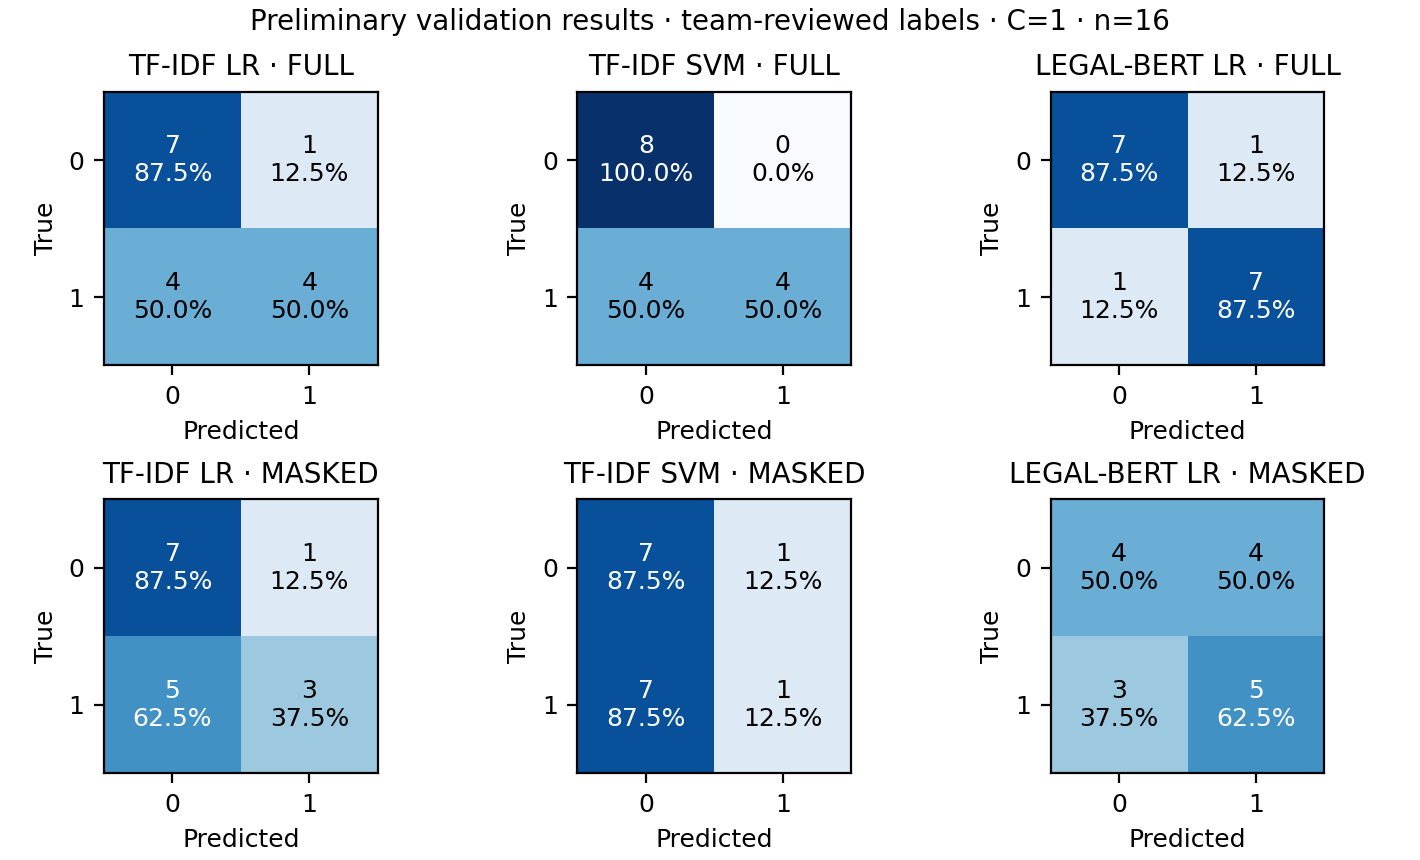

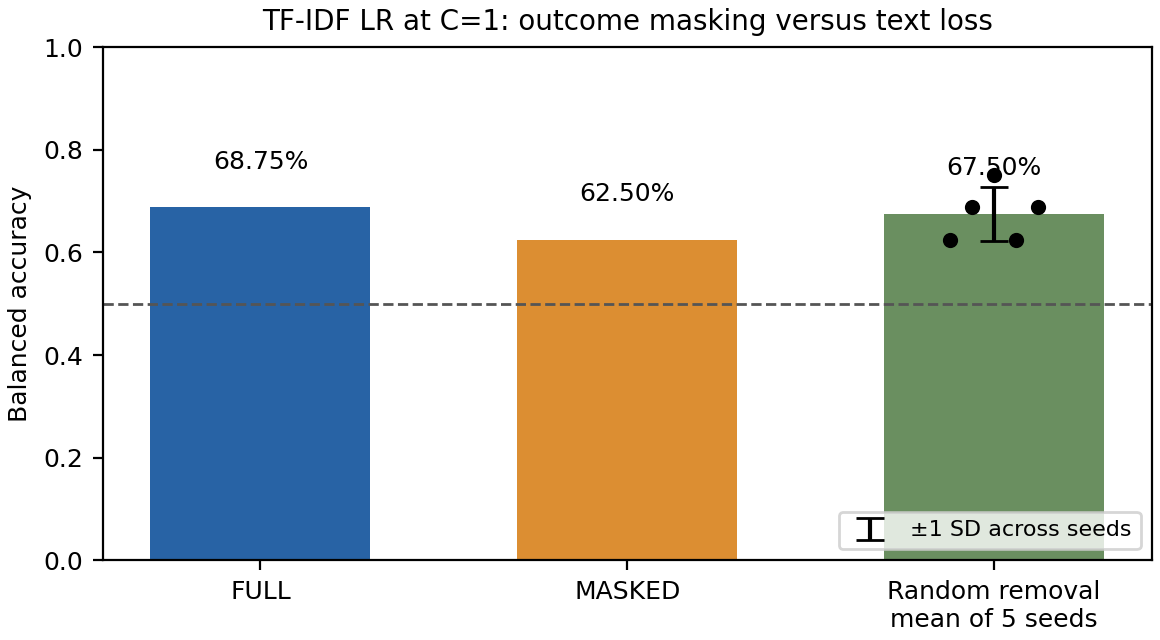

# Initial error analysis on team-reviewed validation cases

These observations use the new fixed-C=1 predictions, full cleaned opinions and exact removed passages. They are interpretations of possible failure modes, not proof of a classifier's internal reasoning. No target or mask was revised after seeing model predictions. The complete 16-case review packet is in `outputs/ERROR_REVIEW_PACKET.md`.

| Case | Observed behavior | Interpretation |
|---|---|---|
| Schneider v. Gap, NY-7855719 (reversed) | All three models are correct on FULL but predict affirmed on MASKED. The mask removes the operative reversal and concluding should-have-granted sentence. | The remaining evidence supports the defendant: the opinion says surveillance showed the plaintiff tripped over her own feet. However, the earlier court had denied the defense motion, so the defendant's appellate success is a reversal. This illustrates why favorable merits reasoning alone does not determine affirmed/reversed; the earlier ruling matters too. |
| Zubillaga, NY-4929051 (reversed) | Both TF-IDF models predict affirmed in both conditions. LEGAL-BERT changes from correct on FULL to incorrect on MASKED. | The longest validation opinion has multiple orders, a default ruling, adjournment history and warning-sign merits analysis. Direct reversal synopses are removed while extensive procedural history remains. All chunks were used, so loss of all text after token 512 cannot explain this error. Ancillary procedural outcomes remain under the frozen mask. |
| Yerry, NY-7857572 (reversed) | Both TF-IDF models predict affirmed in both conditions; LEGAL-BERT is correct in both. | The opinion distinguishes the original summary judgment from appellate findings about notice and remedial measures. Becca's v2 preserves an evidentiary approval sentence that the old trial mask removed. This supports inspecting what was retained, rather than assuming every reference to an approved lower-court action states the whole appeal's result. |
| Cheprakova, NY-9355453 (affirmed) | Both TF-IDF models are correct in both conditions. LEGAL-BERT changes from correct on FULL to incorrect on MASKED. | The main reasoning that the plaintiff could not identify the cause of the fall remains. Unlike the older trial mask, v2 also preserves the first historical trial ruling. An error can therefore remain even after improving preservation; useful retained reasoning does not guarantee correct classification in a small training set. |

For the MASKED LR model, training coefficients associate terms such as `dept`, `1st dept` and `steps` with affirmed, and `parking`, `rug` and `trivial` with reversed. Common language and citation style may encode case mix or court writing habits. A cited department is not necessarily the deciding department; these are associations, not causal findings.

At fixed C, MASKED reversal recall is 3/8 for LR, 1/8 for SVM, and 5/8 for LEGAL-BERT. LEGAL-BERT's higher reversal recall is offset by only 4/8 affirmance recall. Accuracy or an isolated class recall therefore cannot summarize the comparison. The required confusion matrices and macro F1 expose that tradeoff.

The examples do not establish a stable model ranking, and the old and new runs differ in data selection and preprocessing. Only within-run comparisons share the same examples and settings. The validation set has been reused during development, so the final test period must remain independent.


In [13]:
import presentation
presentation.make_figures()
display(Image(filename=str(p.OUT/'figures/confusion_matrices.png')))
display(Image(filename=str(p.OUT/'figures/ablation.png')))
observations = p.HERE/'ERROR_OBSERVATIONS.md'
if observations.exists(): display(Markdown(observations.read_text(encoding='utf8')))

## 14. Verify the end-to-end system

Recompute every saved metric from case-level predictions; verify shared IDs, exact random-removal budgets, train-only vocabulary, valid encoder feature shapes and absence of test predictions. These checks establish pipeline consistency; they do not prove complete legal eligibility or exhaustive removal of outcome cues.

In [14]:
display(p.validate_results())

{'status': 'passed',
 'model_C_conditions': 34,
 'validation_cases': 16,
 'development_cases': 102,
 'matched_random_budgets': True,
 'training_only_vocabulary': True,
 'feature_shapes_valid': True,
 'test_predictions': 0,
 'review_status': 'team_reviewed'}

## 15. Checkpoint status and next steps

- **Working MVP:** deterministic data integration, versioned text variants, three learned models and a majority baseline, predictions, metrics, figures and report.
- **Data/evaluation pipeline:** 120 team-reviewed selected candidates; 119 assigned, with one unresolved family hold. Train 86, validation 16, test 17 reserved. Stable case/family IDs and training-only fitting.
- **Baselines:** majority, TF-IDF LR, TF-IDF SVM; frozen LEGAL-BERT is the representation comparison.
- **First experiments:** FULL/MASKED comparisons, fixed-C ablation, five-seed LR random removal, small C-grid search, lengths and error review.
- **Preliminary results:** shown above with required metrics and uncertainty; the sample is too small for strong ranking or prospective-prediction claims.

The reviewed pool is below the proposal's 150-case MVP target; the pipeline is operational and this ungraded checkpoint demonstrates experimental evidence. Next, resolve outstanding cases/companions, expand reviewed coverage, document the evaluation-review protocol, and freeze the final pipeline before a single final-test evaluation. More complex models are secondary to these checks.

References: [Medvedeva & McBride (2023)](https://aclanthology.org/2023.nllp-1.9/), [Chalkidis et al. (2020)](https://aclanthology.org/2020.findings-emnlp.261/), [Pangakis & Wolken (2024)](https://arxiv.org/abs/2406.17633).